# 02 · From one neuron to a small neural network

This notebook follows the ladder of the JGI course
[Introduction to AI](https://bristol-training.github.io/intro-to-ai/) — perceptron → activation
function → gradient descent → backpropagation → multi-layer perceptron — using the same splice-site
data as notebook 01. The maths behind it is laid out in Steven Morse's
[Neural Networks for a beginner (Part I)](https://stmorse.github.io/journal/Beginner-NN-Part-I.html);
I'll point to the relevant bit as we go.

**Plan**

1. Build a single neuron and train it with gradient descent, writing the derivative out by hand.
2. Let PyTorch's autograd compute the same derivative and check we get the same answer.
3. Look at what the neuron learned.
4. Add a hidden layer (a real multi-layer perceptron) and compare with the logistic-regression baseline.
5. Ask the network which positions it cares about.

In [1]:
import sys
sys.path.insert(0, "../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from splice_utils import load_splice, one_hot, feature_names, POSITIONS, BASES

torch.manual_seed(0)
np.random.seed(0)

df = load_splice("../data/splice.data")
X = one_hot(df["sequence"])
y3 = df["label"].values                                   # EI / IE / N

# Same split as notebook 01 so the comparison is fair
X_train, X_test, y3_train, y3_test = train_test_split(X, y3, test_size=0.25, random_state=42, stratify=y3)

# Tensors for PyTorch
Xt_train, Xt_test = torch.tensor(X_train), torch.tensor(X_test)
print(Xt_train.shape, Xt_test.shape)

torch.Size([2392, 240]) torch.Size([798, 240])


## 1. One neuron, by hand

Morse describes a neuron as two steps: **aggregate** then **activate**.

$$z = \sum_j w_j x_j + b, \qquad a = f(z)$$

For a yes/no question we use the **sigmoid** activation $f(z) = 1/(1+e^{-z})$, which squashes any
number into (0, 1) so we can read $a$ as a probability. Let's start with a yes/no question:
*is there a splice junction in this window at all?* (EI or IE → 1, N → 0).

**Loss.** Morse uses squared error because his post is about regression. For a probability output
the natural loss is **binary cross-entropy**: $\ell = -[y\log a + (1-y)\log(1-a)]$. It punishes a
confident wrong answer much more than squared error does.

**Gradient.** Morse's whole post is about computing $\partial \ell / \partial w$ with the chain rule.
For one sigmoid neuron with cross-entropy the chain collapses to something remarkably tidy:

$$\frac{\partial \ell}{\partial z} = a - y, \qquad
  \frac{\partial \ell}{\partial w_j} = (a - y)\,x_j, \qquad
  \frac{\partial \ell}{\partial b} = a - y .$$

Averaged over all $n$ training sequences that is $\nabla_w = \tfrac{1}{n} X^\top (a - y)$.
Then **gradient descent** is just: $w \leftarrow w - \eta\,\nabla_w$ (Morse's "Idea 1"), repeated.

In [2]:
yb_train = torch.tensor((y3_train != "N").astype(np.float32)).unsqueeze(1)   # 1 = splice site, 0 = none
yb_test  = torch.tensor((y3_test  != "N").astype(np.float32)).unsqueeze(1)

def sigmoid(z):
    return 1 / (1 + torch.exp(-z))

def bce(a, y):
    eps = 1e-7                                            # avoid log(0)
    return -(y * torch.log(a + eps) + (1 - y) * torch.log(1 - a + eps)).mean()

n_features = Xt_train.shape[1]
w = torch.zeros(n_features, 1)                            # 240 weights, one per (position, base)
b = torch.zeros(1)
lr, epochs = 0.5, 400
history_manual = []

for epoch in range(epochs):
    z = Xt_train @ w + b                                  # aggregate
    a = sigmoid(z)                                        # activate
    loss = bce(a, yb_train)
    history_manual.append(loss.item())

    grad_z = (a - yb_train) / len(yb_train)               # ∂ℓ/∂z, averaged
    grad_w = Xt_train.T @ grad_z                          # ∂ℓ/∂w
    grad_b = grad_z.sum()                                 # ∂ℓ/∂b
    w -= lr * grad_w                                      # the gradient step
    b -= lr * grad_b

a_test = sigmoid(Xt_test @ w + b)
acc_manual = ((a_test > 0.5).float() == yb_test).float().mean().item()
print(f"hand-written neuron — final training loss {history_manual[-1]:.4f},  test accuracy {acc_manual:.3f}")

hand-written neuron — final training loss 0.1098,  test accuracy 0.934


## 2. The same neuron with autograd

Writing the derivative out by hand is fine for one neuron. For a network with thousands of weights
it isn't — which is where **backpropagation** (Morse's "Idea 2") comes in: store every intermediate
value on the forward pass, then work backwards applying the chain rule layer by layer.
PyTorch does this for us with `loss.backward()`.

`nn.Linear(240, 1)` is our aggregate step; `BCEWithLogitsLoss` folds the sigmoid into the loss (it's
numerically safer that way). Same learning rate, same number of steps, same zero initialisation — we
should land in the same place.

autograd neuron    — final training loss 0.1098,  test accuracy 0.934
max |difference| between the two weight vectors: 2.384185791015625e-07


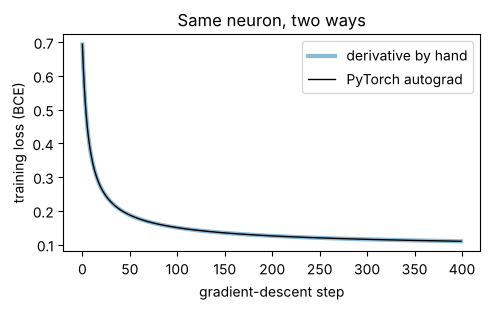

In [3]:
torch.manual_seed(0)
neuron = nn.Linear(n_features, 1)
nn.init.zeros_(neuron.weight); nn.init.zeros_(neuron.bias)

loss_fn = nn.BCEWithLogitsLoss()
optimiser = torch.optim.SGD(neuron.parameters(), lr=lr)
history_autograd = []

for epoch in range(epochs):
    optimiser.zero_grad()                 # forget last step's gradients
    z = neuron(Xt_train)                  # forward pass (aggregate)
    loss = loss_fn(z, yb_train)           # sigmoid + cross-entropy
    loss.backward()                       # backpropagation: fills in .grad for every parameter
    optimiser.step()                      # w ← w − lr · grad
    history_autograd.append(loss.item())

with torch.no_grad():
    acc_autograd = ((neuron(Xt_test) > 0).float() == yb_test).float().mean().item()
print(f"autograd neuron    — final training loss {history_autograd[-1]:.4f},  test accuracy {acc_autograd:.3f}")
print("max |difference| between the two weight vectors:", (neuron.weight.detach().T - w).abs().max().item())

fig, ax = plt.subplots(figsize=(5, 3.2))
ax.plot(history_manual, label="derivative by hand", lw=3, alpha=0.5)
ax.plot(history_autograd, label="PyTorch autograd", lw=1, color="black")
ax.set(xlabel="gradient-descent step", ylabel="training loss (BCE)", title="Same neuron, two ways")
ax.legend()
plt.tight_layout()
plt.savefig("../figures/02_neuron_two_ways.png", dpi=150)
plt.show()

## 3. What did the neuron learn?

A single neuron has one weight per (position, base). Laid out as a 4 × 60 grid, that *is* a picture
of what the model thinks a splice junction looks like. Because this neuron answers "EI **or** IE?",
it should find both signals: the **GT** that starts an intron (+1, +2) and the **AG** that ends one
(−2, −1).

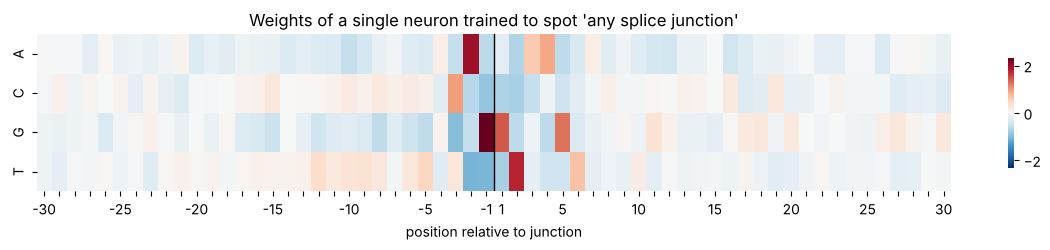

largest positive weights: ['-1:G (+2.32)', '-2:A (+1.98)', '+2:T (+1.78)', '+1:G (+1.44)', '+5:G (+1.25)', '-3:C (+0.96)']


In [4]:
names = feature_names()
W = neuron.weight.detach().numpy().ravel()

def weight_heatmap(W, title, ax):
    grid = W.reshape(60, 4).T
    vmax = np.abs(grid).max()
    sns.heatmap(grid, cmap="RdBu_r", center=0, vmin=-vmax, vmax=vmax, ax=ax, yticklabels=BASES,
                xticklabels=[str(p) if p % 5 == 0 or abs(p) == 1 else "" for p in POSITIONS],
                cbar_kws={"shrink": 0.7})
    ax.axvline(30, color="black", lw=1)
    ax.set(title=title, xlabel="position relative to junction")

fig, ax = plt.subplots(figsize=(12, 2.6))
weight_heatmap(W, "Weights of a single neuron trained to spot 'any splice junction'", ax)
plt.tight_layout()
plt.savefig("../figures/02_neuron_weights.png", dpi=150)
plt.show()

top = np.argsort(W)[::-1][:6]
print("largest positive weights:", [f"{names[i]} ({W[i]:+.2f})" for i in top])

## 4. Add a hidden layer: a multi-layer perceptron

One neuron can only draw a straight line through feature space (it *is* logistic regression). A
**hidden layer** of neurons, each with a non-linear activation, lets the network combine bases — e.g.
"G at +1 *and* T at +2 *and* a pyrimidine-rich stretch before" — which a sum of independent weights
can't quite express.

Our MLP: 240 inputs → 32 hidden neurons with **ReLU** ($f(z)=\max(0,z)$) → 3 outputs (EI, IE, N).
For three classes we use softmax + cross-entropy, which `nn.CrossEntropyLoss` does in one go.

Two practical changes from Part 1, both from the course:

* **Random initialisation.** With ReLU, starting all weights at zero means every hidden neuron is
  identical and stays identical (Morse's "practical consideration 1"). PyTorch's default init handles this.
* **Mini-batches.** Instead of one gradient step over all 2,392 sequences per epoch, we take a step
  after every 64 — *stochastic* gradient descent. It's noisier but gets there faster.

MLP test accuracy after 40 epochs: 0.940


Logistic regression baseline:              0.937


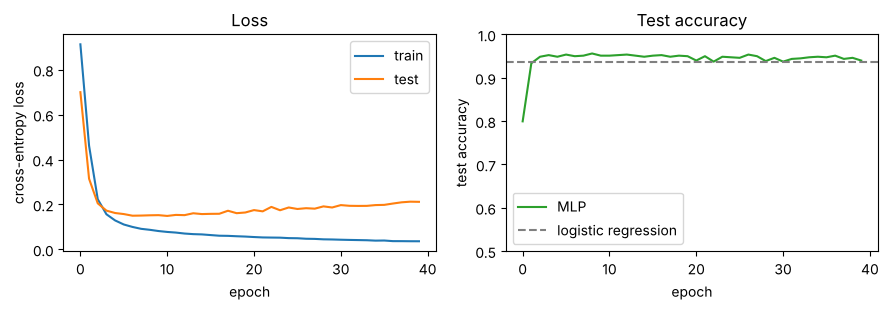

In [5]:
classes = ["EI", "IE", "N"]
y_train_idx = torch.tensor([classes.index(c) for c in y3_train])
y_test_idx  = torch.tensor([classes.index(c) for c in y3_test])

torch.manual_seed(0)
mlp = nn.Sequential(
    nn.Linear(n_features, 32),
    nn.ReLU(),
    nn.Linear(32, 3),
)
loss_fn = nn.CrossEntropyLoss()
optimiser = torch.optim.SGD(mlp.parameters(), lr=0.1)

batch_size, epochs = 64, 40
train_loss, test_loss, test_acc = [], [], []

for epoch in range(epochs):
    mlp.train()
    perm = torch.randperm(len(Xt_train))                 # shuffle each epoch
    running = 0.0
    for start in range(0, len(perm), batch_size):
        idx = perm[start:start + batch_size]
        optimiser.zero_grad()
        loss = loss_fn(mlp(Xt_train[idx]), y_train_idx[idx])
        loss.backward()
        optimiser.step()
        running += loss.item() * len(idx)
    train_loss.append(running / len(perm))

    mlp.eval()
    with torch.no_grad():
        logits = mlp(Xt_test)
        test_loss.append(loss_fn(logits, y_test_idx).item())
        test_acc.append((logits.argmax(1) == y_test_idx).float().mean().item())

acc_mlp = test_acc[-1]
print(f"MLP test accuracy after {epochs} epochs: {acc_mlp:.3f}")

# The baseline from notebook 01, refitted here in two lines so the numbers sit side by side
baseline = LogisticRegression(max_iter=2000).fit(X_train, y3_train)
acc_logreg = baseline.score(X_test, y3_test)
print(f"Logistic regression baseline:              {acc_logreg:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
axes[0].plot(train_loss, label="train"); axes[0].plot(test_loss, label="test")
axes[0].set(xlabel="epoch", ylabel="cross-entropy loss", title="Loss"); axes[0].legend()
axes[1].plot(test_acc, color="tab:green", label="MLP")
axes[1].axhline(acc_logreg, color="grey", ls="--", label="logistic regression")
axes[1].set(xlabel="epoch", ylabel="test accuracy", title="Test accuracy", ylim=(0.5, 1.0)); axes[1].legend()
plt.tight_layout()
plt.savefig("../figures/02_mlp_training.png", dpi=150)
plt.show()

              precision    recall  f1-score   support

          EI       0.92      0.93      0.92       192
          IE       0.90      0.94      0.92       192
           N       0.97      0.95      0.96       414

    accuracy                           0.94       798
   macro avg       0.93      0.94      0.93       798
weighted avg       0.94      0.94      0.94       798



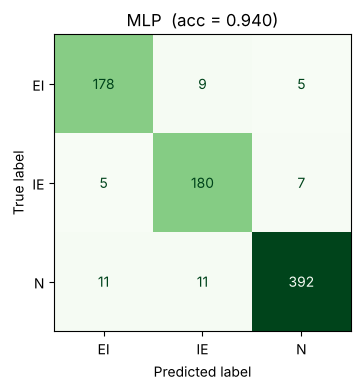

In [6]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

with torch.no_grad():
    pred_mlp = np.array(classes)[mlp(Xt_test).argmax(1).numpy()]
print(classification_report(y3_test, pred_mlp))

fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay.from_predictions(y3_test, pred_mlp, ax=ax, colorbar=False, cmap="Greens")
ax.set_title(f"MLP  (acc = {acc_mlp:.3f})")
plt.tight_layout()
plt.savefig("../figures/02_confusion_mlp.png", dpi=150)
plt.show()

## 5. Which positions does the network look at?

With a hidden layer the weights no longer map one-to-one onto bases, but we can still ask a coarser
question: *how much total weight does the first layer put on each position?* Summing $|W|$ over the 32
hidden neurons and the 4 bases gives one number per position. We'd hope the junction (−2 … +2)
dominates, with a secondary bump upstream where the polypyrimidine tract sits.

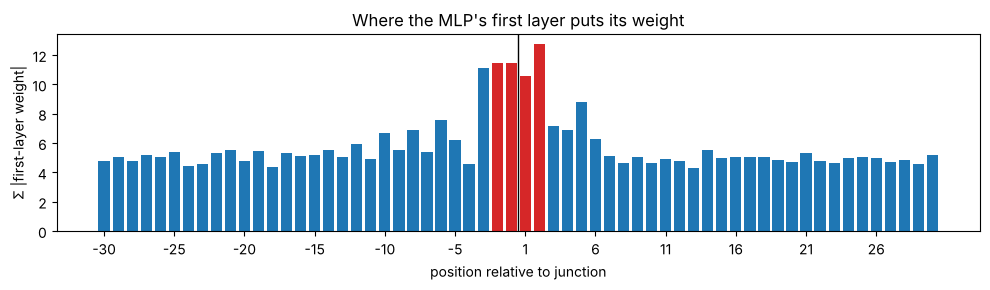

positions with most weight: [2, -2, -1, -3, 1, 5]


In [7]:
W1 = mlp[0].weight.detach().numpy()                     # shape (32 hidden, 240 inputs)
per_position = np.abs(W1).sum(axis=0).reshape(60, 4).sum(axis=1)

fig, ax = plt.subplots(figsize=(10, 3))
colors = ["tab:red" if abs(p) <= 2 else "tab:blue" for p in POSITIONS]
ax.bar(range(60), per_position, color=colors)
ax.axvline(29.5, color="black", lw=1)
ax.set_xticks(range(0, 60, 5)); ax.set_xticklabels([str(POSITIONS[i]) for i in range(0, 60, 5)])
ax.set(xlabel="position relative to junction", ylabel="Σ |first-layer weight|",
       title="Where the MLP's first layer puts its weight")
plt.tight_layout()
plt.savefig("../figures/02_mlp_position_importance.png", dpi=150)
plt.show()

order = np.argsort(per_position)[::-1][:6]
print("positions with most weight:", [POSITIONS[i] for i in order])

## What I learnt
* A single neuron trained by hand-written gradient descent and one trained by PyTorch's autograd end
  up with the same weights — backpropagation isn't magic, it's the chain rule done systematically.
* That neuron's weight map is a recognisable picture of the GT…AG splice consensus. The model learned
  biology it was never told.
* Look at the loss plot: training loss keeps falling while test loss turns upwards after a handful of
  epochs. That is **overfitting** — the 32 hidden neurons have enough capacity to start memorising the
  training sequences. Test accuracy barely moves because the extra confidence is mostly spent on
  sequences it already gets right; this is why people stop early or add regularisation
  (Morse's "practical considerations" 2 and 3).
* A one-hidden-layer MLP gets a similar or slightly better test accuracy than logistic regression on
  this problem. That's a useful lesson too: for a signal that's mostly additive, a linear model is
  already very strong, and extra capacity buys little without more data or more structure
  (the 1992 KBANN paper this dataset comes from reported much the same for its backprop network).

**Things to try next** (each one is a single change to the code above): a different learning rate
(see what 0.01 or 1.0 does to the loss curve), more or fewer hidden neurons, more epochs, or a
second hidden layer. Those are exactly the knobs the *Learning rate* section of the course is about.